# Feature Engineering — Home Credit Credit Risk Model Stability

| Seção | Descrição |
|---|---|
| 1.0 | Seleção de Features e Mapeamento de Fontes |
| 2.0 | Processamento Depth 0 (Merges Estáticos) |
| 3.0 | Processamento Depth 1/2 (Agregações de Histórico) |
| 4.0 | Divisão Temporal (OOT + Split 70/30) |
| 4.4 | Shadow Features (Pós-Split) |
| 5.0 | Engenharia de Features Avançada |
| 5.1 | Rácios de Alavancagem e Esforço Financeiro |
| 5.2 | Dinâmica de Atrasos (DPD Momentum) |
| 5.3 | Intensidade de Busca e Sinais Anómalos |
| 5.4 | Flags Binárias de Risco Crítico |
| 5.5 | Features Avançadas, Sazonais e Macroeconómicas |
| 6.0 | Análise Categórica e One-Hot Encoding |
| 7.0 | Limpeza de Esparsidade e Imputação |
| 7.1 | Remoção de Features com >70% Nulos |
| 7.2 | Imputação Zero-Lógico |
| 7.3 | Análise de Nulos Residuais |
| 7.4 | Normalização via RobustScaler (Anti-Leakage) |
| 8.0 | Diagnóstico Univariado — Information Value (IV) |
| 8.1 | Análise de Correlação de Pearson entre Pares |
| 8.2 | Análise VIF (Variance Inflation Factor) |
| 9.0 | Validação de Esquema e Exportação (Parquet) |
| 10.0 | Dicionário Técnico das Features Finais |

_______

## 1.0 Seleção de Features e Mapeamento de Fontes

**Objetivo:** Reduzir o espaço original (>1.400 variáveis) para um núcleo inicial de **50 colunas**, guiado por hipóteses qualitativas de risco de crédito.

### Estratégia de Seleção

| Grupo | Racional de Negócio | Exemplos |
|---|---|---|
| **Scores e Risco Externo** | Julgamento do mercado (Bureau) sobre o cliente | `score_940`, `riskassesment_302T`, `riskassesment_940T` |
| **Histórico de Atrasos (DPD)** | Melhor preditor de comportamento futuro é o passado | `maxdpdlast12m_727P`, `dpdmax_757P`, `pmts_dpd_1073P` |
| **Endividamento e Montantes** | Capacidade de suportar nova linha de crédito | `totaldebt_9A`, `currdebt_22A`, `credamount_770A` |
| **Rendimento e Emprego** | Estabilidade do fluxo de caixa | `mainoccupationinc_384A`, `commnoinclast6m_3546845L` |
| **Rejeições e Aplicações** | Urgência financeira e alertas de fraude | `numrejects9m_859L`, `applicationscnt_867L`, `clientscnt_887L` |
| **Contratos Anteriores** | Maturidade e fidelidade com a instituição | `numactiverelcontr_750L`, `numinstpaid_4499208L`, `pmtnum_8L` |

### Arquitetura (Depth)

- **Depth 0** — atributos estáticos, únicos por cliente no momento da decisão → `LEFT JOIN` direto por `case_id`.
- **Depth 1/2** — histórico longitudinal (ex.: uma linha por prestação) → exige agregações (`max`, `sum`, `mean`) por `case_id` antes do merge final.

_________

In [10]:
# TOP 50 COLUNAS SELECIONADAS (ESTRITAMENTE PRÉ-DECISÃO / VALORES QUALITATIVOS )
colunas_selecionadas = [
    # ================= SCORES DE BUREAU (PRÉ-APROVAÇÃO) =================
    'score_940',                      # Score de crédito do bureau calculado ANTES desta aplicação.
    'riskassesment_302T',             # Avaliação de risco externa já existente no sistema.
    'riskassesment_940T',             # Segunda métrica de risco do bureau no momento da consulta.

    # ================= HISTÓRICO PASSADO DE ATRASOS (BUREAU) =================
    'maxdpdlast12m_727P',             # Maior atraso nos últimos 12 meses (histórico).
    'maxdpdlast24m_143P',             # Maior atraso nos últimos 24 meses (histórico).
    'avgdbddpdlast24m_3658932P',      # Média de dias de atraso nos últimos 2 anos.
    'maxdbddpdlast1m_3658939P',       # Atraso máximo detetado no mês anterior ao pedido de crédito.
    'pctinstlsallpaidlat10d_839L',    # % de prestações passadas pagas com >10 dias de atraso.
    'pctinstlsallpaidlate6d_3546844L',# % de prestações passadas pagas com >6 dias de atraso.
    'numinstlswithdpd5_4187116L',     # Número de prestações antigas com >5 dias de atraso.
    'actualdpd_943P',                 # DPD real registado num contrato de crédito ANTERIOR.
    'dpdmax_139P',                    # DPD máximo em créditos antigos ainda ativos no bureau.
    'dpdmax_757P',                    # DPD máximo em créditos antigos já encerrados.
    'pmts_dpd_1073P',                 # Consolidado de atrasos passados.

    # ================= ENDIVIDAMENTO PRÉ-EXISTENTE (NO MOMENTO DA APLICAÇÃO) =================
    # ATENÇÃO: Estas variáveis representam o que o cliente JÁ DEVIA
    # no mercado no momento exato em que preencheu a nova proposta de crédito.
    'totaldebt_9A',                   # Dívida total consolidada em outras instituições no dia do pedido.
    'currdebt_22A',                   # Saldo devedor pré-existente capturado na hora da análise.
    'totaldebtoverduevalue_178A',     # Montante em atraso financeiro de outros contratos ativos.
    'totaldebtoverduevalue_718A',     # Montante em atraso de contratos passados/fechados.
    'totaloutstanddebtvalue_39A',     # Dívida pendente de outros contratos (Bureau).
    'totaloutstanddebtvalue_668A',    # Dívida pendente de contratos fechados (Bureau).
    'debtoutstand_525A',              # Capital em dívida remanescente de contratos anteriores.
    'overdueamountmax_155A',          # Maior valor já registado em atraso no histórico do cliente.
    'overdueamountmax_35A',           # Maior valor em atraso em contratos encerrados.
    'residualamount_1093A',           # Saldo final a liquidar de dívidas passadas.
    'credamount_770A',                # Valor do crédito que está a ser SOLICITADO AGORA.
    'annuity_780A',                   # Valor da prestação proposta para o NOVO crédito.
    'amount_1115A',                   # Montantes de crédito antigo ativos no bureau.
    'credlmt_935A',                   # Limites de cartões de crédito que o cliente JÁ possui.
    'outstandingdebt_522A',           # Dívida pendente de empréstimos antigos.
    'monthlyinstlamount_332A',        # Custo mensal atual do cliente com outras prestações.
    'pmts_overdue_1140A',             # Valores históricos que ficaram em atraso.

    # ================= RENDIMENTO E PERFIL SÓCIO-ECONÓMICO =================
    'mainoccupationinc_384A',         # Rendimento principal declarado no ato da aplicação.
    'incometype_1044T',               # Tipo de rendimento (assalariado, pensionista, etc).
    'empl_employedfrom_271D',         # Data de início do emprego atual.
    'empl_employedtotal_800L',        # Tempo total de experiência profissional declarada.
    'commnoinclast6m_3546845L',       # Alerta de quebra de rendimento nos 6 meses anteriores à aplicação.
    'clientscnt_887L',                # Alerta de fraude: Quantos clientes usam o mesmo contacto/empregador.

    # ================= COMPORTAMENTO DE BUSCA E REJEIÇÕES PASSADAS =================
    'numrejects9m_859L',              # Quantas vezes o cliente foi rejeitado nos últimos 9 meses.
    'days30_165L',                    # Substituiu o texto da rejeição: Consultas ao bureau nos últimos 30 dias.
    'applicationscnt_867L',           # Consultas associadas ao mesmo telemóvel (alerta de fraude).
    'applicationscnt_629L',           # Consultas associadas ao mesmo empregador.
    'forquarter_462L',                # Consultas feitas ao bureau de crédito no trimestre anterior.
    'days180_256L',                   # Consultas feitas ao bureau nos últimos 180 dias.

    # ================= HISTÓRICO DE BONS PAGAMENTOS =================
    'numinstunpaidmaxest_4493212L',   # Prestações máximas não pagas em créditos antigos.
    'numinstpaid_4499208L',           # Número total de prestações antigas pagas com sucesso.
    'posfpd30lastmonth_3976960P',     # Se o cliente falhou a 1ª prestação noutro crédito no mês passado.
    'numactiverelcontr_750L',         # Quantidade de contratos (ex: cartões) ativamente em uso hoje.
    'pmtnum_8L',                      # Histórico de número de pagamentos efetuados.
    'tenor_203L',                     # Prazo original de empréstimos contratados no passado.
    'credacc_transactions_402L',      # Contagem de transações em contas de crédito anteriores.
]

print(f"Total de colunas selecionadas: {len(colunas_selecionadas)}")

Total de colunas selecionadas: 50


## 2.0 Processamento Depth 0 (Merges Estáticos)

**Objetivo:** Enriquecer a `train_base` com atributos estáticos, preservando rigorosamente a granularidade (`case_id` único).

### Fontes Consultadas

| Tabela | Descrição | Colunas-Chave |
|---|---|---|
| `train_base` | Tabela mestre — 1 linha por `case_id` | `case_id`, `date_decision`, `MONTH`, `target` |
| `train_static_0` | Atributos internos do cliente | `mainoccupationinc_384A`, `incometype_1044T`, `empl_*` |
| `train_static_cb_0` | Atributos do Bureau de crédito | `score_940`, `riskassesment_*` |

### Protocolo (`merge_depth_0`)

1. **`LEFT JOIN`** estrito por `case_id` com cada tabela estática.
2. **Projeção de colunas:** apenas as 50 colunas de `colunas_selecionadas` são carregadas (`pq.read_table(columns=...)`), reduzindo I/O.
3. **Auditoria de granularidade automática** (via `assert`):
   - `linhas_originais == linhas_finais` → sem explosão cartesiana.
   - `linhas_finais == case_id.nunique()` → unicidade preservada.
4. **Cleanup explícito:** `del df_static_*` + `gc.collect()` após o merge, para liberar memória das tabelas intermediárias.

### Saída
- Shape: `(1526659, 30)` — 25 colunas originais + 5 enriquecidas.

### Nota sobre Cobertura

Nem todas as 50 colunas selecionadas existem em `train_static_0` / `train_static_cb_0`. O `merge_depth_0` **descarta silenciosamente** as ausentes (via compreensão de lista) — não lança erro. As colunas efetivamente adicionadas por este passo estão listadas na Seção 10.1.

______

In [11]:
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')
from statsmodels.tools.sm_exceptions import SingularMatrixWarning
warnings.filterwarnings('ignore', category=SingularMatrixWarning)

# 1. Resolucao robusta da raiz do projeto (compativel com Colab e Local)
current_dir = Path(os.getcwd()).resolve()
if (current_dir / 'src').exists():
    PROJECT_ROOT = current_dir
elif (current_dir / 'Projeto_06' / 'src').exists():
    PROJECT_ROOT = current_dir / 'Projeto_06'
elif (current_dir.parent / 'src').exists():
    PROJECT_ROOT = current_dir.parent
elif Path('/content/Projeto_06/src').exists():
    PROJECT_ROOT = Path('/content/Projeto_06')
else:
    raise FileNotFoundError("Diretorio raiz contendo a pasta 'src' nao foi encontrado.")

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Diretorio de trabalho configurado: {os.getcwd()}")
print("Caminhos de busca do Python atualizados com sucesso.")

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import RobustScaler

# 2. Importacoes modulares especializadas do pacote src/
from src.pipeline import (
    setup_environment,
    download_competition,
    get_table_groups,
    carregar_familia,
    downcast_train_base,
    merge_depth_0,
    descobrir_colunas_depth_1,
    merge_depth_1,
    criar_shadow_features,
    criar_ratios,
    criar_dpd_momentum,
    criar_intensidade,
    criar_flags_risco_critico,
    criar_features_linha,
    imputar_zero_logico,
    calcular_iv_dataset,
    analisar_multicolinearidade_pares,
    analisar_vif,
    validar_esquema,
    auditar_anti_leakage,
)
from src.plots import (
    analisar_valores_nulos,
)

print("Modulos do pacote src/ importados com sucesso!")

# Setup
PROJECT_ROOT = setup_environment(str(PROJECT_ROOT))
base_dir = download_competition()
train_dir = base_dir / 'parquet_files' / 'train'
grupos_tabelas = get_table_groups(train_dir)


Diretorio de trabalho configurado: /content
Caminhos de busca do Python atualizados com sucesso.
Modulos do pacote src/ importados com sucesso!
Ambiente configurado. Token Kaggle carregado.
Dados localizados em: /root/.cache/kagglehub/competitions/home-credit-credit-risk-model-stability
Foram mapeadas 17 familias de tabelas.


In [12]:
df_base = carregar_familia(grupos_tabelas, 'train_base')
df_base = downcast_train_base(df_base)

df_master= merge_depth_0(df_base, grupos_tabelas, colunas_selecionadas)
print(f"\nShape final Depth 0: {df_master.shape}")
display(df_master.head())

Carregando 'train_base' (1 arquivo(s))...
Carregando tabelas de Depth 0...
Carregando 'train_static_0' (2 arquivo(s))...
Carregando 'train_static_cb_0' (1 arquivo(s))...
Colunas em static_0: 20
Colunas em static_cb_0: 5

Auditoria Depth 0: 1,526,659 -> 1,526,659 linhas
Granularidade preservada. Shape: (1526659, 30)

Shape final Depth 0: (1526659, 30)


,case_id,date_decision,MONTH,WEEK_NUM,target,maxdpdlast12m_727P,maxdpdlast24m_143P,avgdbddpdlast24m_3658932P,maxdbddpdlast1m_3658939P,pctinstlsallpaidlat10d_839L,...,applicationscnt_629L,numinstunpaidmaxest_4493212L,numinstpaid_4499208L,posfpd30lastmonth_3976960P,numactiverelcontr_750L,riskassesment_302T,riskassesment_940T,days30_165L,forquarter_462L,days180_256L
0,0,2019-01-03,201901,0,0,0.0,0.0,NaN,NaN,NaN,...,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
1,1,2019-01-03,201901,0,0,0.0,0.0,NaN,NaN,NaN,...,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
2,2,2019-01-04,201901,0,0,0.0,0.0,NaN,NaN,NaN,...,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
3,3,2019-01-03,201901,0,0,0.0,0.0,NaN,NaN,NaN,...,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
4,4,2019-01-04,201901,0,1,0.0,0.0,NaN,NaN,NaN,...,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN


## 3.0 Processamento Depth 1/2 (Agregações de Histórico)

**Objetivo:** Achatar matrizes longitudinais (histórico de prestações, transações, contratos) em vetores transversais por cliente, via `groupby('case_id')`, **com filtro anti-leakage temporal quando possível**.

>
> **Sob nenhuma hipótese pode-se vazar dados no dataset, não podemos enviesar o modelo**
> 

Nesse sentido é preferível perder algumas informações do que correr riscos de `vazamento de dados futuros`

### Famílias Mapeadas

O utilitário `descobrir_colunas_depth_1` lê apenas o **schema** (`pq.read_schema`) do primeiro arquivo
de cada família — evitando carregar dados completos só para mapear colunas. Famílias estáticas
(`train_base`, `train_static_0`, `train_static_cb_0`) são explicitamente ignoradas (`SKIP_FAMILIES`).

| Família | Colunas Mapeadas | Estratégia |
|---|---|---|
| `train_applprev_1` | 4 colunas | `max`, `mean`, `sum` |
| `train_credit_bureau_a_1` | 4 colunas | `max`, `sum` |
| `train_credit_bureau_b_1` | 1 coluna | `sum` |

Note que: 

>
> 
> **`train_credit_bureau_a_2` foi descartada a priori.** Essa família não possui coluna de
> data própria (só `pmts_month_*`/`pmts_year_*`) e exigiria filtro por herança de contrato,
> o que permite eventos futuros vazarem para dentro de contratos já iniciados. Trade-off necessário em
> favor de **zero leakage**.

### Cobertura

Das 17 colunas-chave de `agg_map`, **11 foram localizadas** nas tabelas Depth 1/2. As 6 restantes
(`numinstunpaidmaxest_4493212L`, `posfpd30lastmonth_3976960P`, `numactiverelcontr_750L`,
`credamount_770A`, `annuity_780A`, `numinstpaid_4499208L`) já existem em Depth 0 **ou** não foram
localizadas — a auditoria imprime a lista para rastreabilidade.

### Mapa de Agregações (override do notebook)

| Coluna Original | Agregações | Justificativa |
|---|---|---|
| `dpdmax_139P` | `max` | Pior atraso em contratos ativos |
| `dpdmax_757P` | `max` | Pior atraso em contratos encerrados |
| `amount_1115A` | `sum`, `mean` | Exposição total + média no bureau |
| `credlmt_935A` | `sum`, `max` | Limite total + teto de cartão |
| `outstandingdebt_522A` | `sum` | Saldo devedor total pendente |
| `monthlyinstlamount_332A` | `sum` | Custo mensal consolidado |
| `pmtnum_8L` | `sum`, `max` | Volume de pagamentos efetuados |
| `tenor_203L` | `mean`, `max` | Prazo médio + máximo |
| `credacc_transactions_402L` | `sum`, `mean` | Volume de transações |

OBS =
>
>
> **Não presentes no merge final (colunas em `a_2`):** `pmts_dpd_1073P_*`, `pmts_overdue_1140A_*`.

### Filtro Anti-Leakage Temporal (`merge_depth_1`)

Antes de agregar, cada partição é intersectada com `df_master[['case_id', 'date_decision']]` e
**filtrada para manter apenas eventos anteriores à decisão do cliente**:

```python
mask = (data_evento < date_decision) | data_evento.isna()

In [13]:
import pyarrow.parquet as pq

FAMILIAS_INVESTIGAR = [
    'train_credit_bureau_a_2',
    'train_credit_bureau_b_1',
]

for fam in FAMILIAS_INVESTIGAR:
    arquivos = sorted(grupos_tabelas[fam])
    print(f"\n{'='*78}")
    print(f" FAMILIA: {fam}  ({len(arquivos)} particoes)")
    print(f"{'='*78}")
    
    # Pega o schema da primeira particao (deve ser igual para todas)
    schema = pq.read_schema(arquivos[0]).names
    
    # Filtra colunas que parecem ser de data (terminam em 'D' no padrao HC)
    candidatas_data = [
        c for c in schema 
        if c.endswith('D') or 'date' in c.lower() or 'dt' in c.lower()
    ]
    
    print(f"Total de colunas: {len(schema)}")
    print(f"Colunas candidatas a data ({len(candidatas_data)}):")
    for c in sorted(candidatas_data):
        print(f"  - {c}")


 FAMILIA: train_credit_bureau_a_2  (11 particoes)
Total de colunas: 19
Colunas candidatas a data (0):

 FAMILIA: train_credit_bureau_b_1  (1 particoes)
Total de colunas: 45
Colunas candidatas a data (7):
  - contractdate_551D
  - contractmaturitydate_151D
  - dpdmaxdatemonth_804T
  - dpdmaxdateyear_742T
  - lastupdate_260D
  - overdueamountmaxdatemonth_494T
  - overdueamountmaxdateyear_432T


In [14]:
# =============================================================================
# 1. MAPEAMENTOS (sem a_2 — decisão: descartar famílias sem data própria)
# =============================================================================
DATE_COL_MAP = {
    'applprev_1':       'creationdate_885D',
    'credit_bureau_a':  'dateofcredstart_181D',
    'credit_bureau_b':  'contractdate_551D',
    'tax_registry':     'recorddate_4527225D',
    'person_1':         'birthdate_509D',
}

# Famílias sem coluna de data própria são descartadas a priori (zero-leakage).
# train_credit_bureau_a_2 depende de lookup no contrato pai — descartada
# por não garantir filtro linha-a-linha.
FAMILIAS_SEM_DATA_PROPRIA = {'train_credit_bureau_a_2'}

agg_map_depth_1 = {
    'dpdmax_139P':                  ['max'],
    'dpdmax_757P':                  ['max'],
    'pmts_dpd_1073P':               ['max', 'mean'],
    'pmts_overdue_1140A':           ['sum', 'max'],
    'numinstunpaidmaxest_4493212L': ['max'],
    'posfpd30lastmonth_3976960P':   ['max', 'mean'],
    'amount_1115A':                 ['sum', 'mean'],
    'credlmt_935A':                 ['sum', 'max'],
    'outstandingdebt_522A':         ['sum'],
    'monthlyinstlamount_332A':      ['sum'],
    'numactiverelcontr_750L':       ['sum'],
    'credamount_770A':              ['sum', 'max'],
    'annuity_780A':                 ['sum', 'mean'],
    'pmtnum_8L':                    ['sum', 'max'],
    'numinstpaid_4499208L':         ['sum', 'mean'],
    'tenor_203L':                   ['mean', 'max'],
    'credacc_transactions_402L':    ['sum', 'mean'],
}

# =============================================================================
# 2. DESCOBRIR FAMÍLIAS + FILTRAR AS SEM DATA PRÓPRIA
# =============================================================================
col_to_familia, familias = descobrir_colunas_depth_1(
    grupos_tabelas, agg_map=agg_map_depth_1
)

# Remove famílias sem coluna de data própria (não passarão no filtro temporal)
familias_seguras = familias - FAMILIAS_SEM_DATA_PROPRIA
print(f"Famílias descobertas: {sorted(familias)}")
print(f"Famílias descartadas (sem data própria): {sorted(FAMILIAS_SEM_DATA_PROPRIA)}")
print(f"Famílias a usar no merge: {sorted(familias_seguras)}")

# =============================================================================
# 3. AUDITORIA ANTI-LEAKAGE (policy='strict' — apenas famílias seguras)
# =============================================================================
auditoria = auditar_anti_leakage(
    grupos_tabelas,
    date_col_map=DATE_COL_MAP,
    col_to_familia=col_to_familia,
    familias_alvo=familias_seguras,   # audita só o que será merged
    policy='strict',
)
display(auditoria)

Familias depth 1: ['train_applprev_1', 'train_credit_bureau_a_1', 'train_credit_bureau_a_2', 'train_credit_bureau_b_1']
Colunas mapeadas: 11 de 17
Ja na Depth 0 ou ausentes: ['numinstunpaidmaxest_4493212L', 'posfpd30lastmonth_3976960P', 'numactiverelcontr_750L', 'credamount_770A', 'annuity_780A', 'numinstpaid_4499208L']
Famílias descobertas: ['train_applprev_1', 'train_credit_bureau_a_1', 'train_credit_bureau_a_2', 'train_credit_bureau_b_1']
Famílias descartadas (sem data própria): ['train_credit_bureau_a_2']
Famílias a usar no merge: ['train_applprev_1', 'train_credit_bureau_a_1', 'train_credit_bureau_b_1']
 AUDITORIA DE ANTI-LEAKAGE (policy='strict')
[OK] train_applprev_1                 | evento     | OK                     | MANTER
[OK] train_credit_bureau_a_1          | evento     | OK                     | MANTER
[OK] train_credit_bureau_b_1          | evento     | OK                     | MANTER
------------------------------------------------------------------------------------

,familia,tipo_filtro,coluna_data,particoes_ok,status,decisao,justificativa,features_em_risco
0,train_applprev_1,evento,creationdate_885D,2/2,OK,MANTER,Filtro linha-a-linha por 'creationdate_885D'. ...,
1,train_credit_bureau_a_1,evento,dateofcredstart_181D,4/4,OK,MANTER,Filtro linha-a-linha por 'dateofcredstart_181D...,
2,train_credit_bureau_b_1,evento,contractdate_551D,1/1,OK,MANTER,Filtro linha-a-linha por 'contractdate_551D'. ...,


## Decisão anti-leakage

A auditoria `auditar_anti_leakage` classificou cada família Depth 1/2 em três níveis de risco:

| Tipo | Critério | Decisão |
|---|---|---|
| `evento` | Data própria na linha, filtro linha-a-linha | **MANTER** |
| `contrato` | Data herdada via lookup, filtro só no contrato | REMOVER em policy 'strict' |
| `sem_filtro` | Sem coluna de data mapeada | REMOVER |

**Famílias aprovadas:** `applprev_1`, `credit_bureau_a_1`, `credit_bureau_b_1`.
**Família removida:** `credit_bureau_a_2` — filtro apenas a nível de contrato, sem coluna de data própria.

**Custo aceito:** perda de 4 features (`pmts_dpd_1073P_max`, `pmts_dpd_1073P_mean`,
`pmts_overdue_1140A_sum`, `pmts_overdue_1140A_max`) — incluindo a hipotética top-IV do dataset
original. Trade-off explícito em favor da **estabilidade temporal no OOT** e da **ausência de vazamento**.

In [15]:
# =============================================================================
# 4. MERGE DEPTH 1/2 — única chamada, apenas com famílias seguras
# =============================================================================
df_master = merge_depth_1(
    df_master,
    grupos_tabelas,
    col_to_familia,
    familias_seguras,              
    agg_map=agg_map_depth_1,
    date_col_map=DATE_COL_MAP,
    strict_temporal=True,
)
print(f"\nShape final Depth 1/2: {df_master.shape}")


-> train_applprev_1 (4 colunas, 2 arquivos)
   [OK] Filtro Temporal ATIVO: 'creationdate_885D' presente em 2/2 particoes.
     train_applprev_1_0.parquet: 3,887,684 -> 3,799,348 (2.27% eventos futuros removidos)
     train_applprev_1_1.parquet: 2,638,295 -> 2,581,952 (2.14% eventos futuros removidos)
  Shape agregado: (1207863, 8)

-> train_credit_bureau_a_1 (4 colunas, 4 arquivos)
   [OK] Filtro Temporal ATIVO: 'dateofcredstart_181D' presente em 4/4 particoes.
     train_credit_bureau_a_1_0.parquet: 4,108,212 -> 4,108,011 (0.00% eventos futuros removidos)
     train_credit_bureau_a_1_1.parquet: 6,009,192 -> 6,007,966 (0.02% eventos futuros removidos)
     train_credit_bureau_a_1_2.parquet: 3,743,810 -> 3,742,737 (0.03% eventos futuros removidos)
     train_credit_bureau_a_1_3.parquet: 2,079,323 -> 2,078,927 (0.02% eventos futuros removidos)
  Shape agregado: (1386273, 6)

-> train_credit_bureau_b_1 (1 colunas, 1 arquivos)
   [OK] Filtro Temporal ATIVO: 'contractdate_551D' presente em

> **Total de Colunas** Veja que das 50 colunas que tentamos extrair, fechamos em **44 colunas**
> ao final do Depth 1/2 (30 do Depth 0 + 14 do merge histórico).
>
> **Objetivo Atual** Realizar a divisão do dataset e, futuramente, as devidas features engineerings

________
## 4.0 Divisão Temporal (OOT + Split 70/30 + K-Fold)

**Objetivo:** Separar cronologicamente para prevenção de *data leakage* e preparar as bases de treino, validação interna e avaliação OOT.

### 4.1 Corte Out-of-Time (OOT)

- **`MONTH >= 202007`** → `df_oot` (meses futuros, isolados).
- **`MONTH < 202007`** → `df_hist` (histórico para treino).
- **`df_master_snapshot`** — cópia do estado pré-split, preservada para auditoria (exportada como `master_table.parquet` na Seção 9.1).

**Racional:** simula o cenário real de produção — o modelo é treinado no passado e avaliado em dados futuros nunca vistos.

### 4.2 Split Estratificado 70/30

- `train_test_split(stratify='target')` garante que a taxa de default permaneça idêntica entre Train e Test.
- `random_state=42` para reprodutibilidade.

### 4.3 Stratified K-Fold (5 folds)

- Configurado para consumo no `03_Modeling.ipynb`, permitindo *tuning* de hiperparâmetros **sem contaminar o OOT**.

### Distribuição Esperada

| Conjunto | Linhas | Período | Default Rate |
|---|---|---|---|
| Treino | 963.493 (70% do hist.) | 201901–202006 | ~3,26% |
| Teste | 412.926 (30% do hist.) | 201901–202006 | ~3,26% |
| OOT | 150.240 | 202007–202010 | ~2,11% |

In [16]:
# =============================================================================
# 4.1 FILTRO OUT-OF-TIME (OOT)
# =============================================================================
# Snapshot pré-split para auditoria (consumido pela exportação na Seção:

OOT_START = 202007
df_oot = df_master[df_master['MONTH'] >= OOT_START].copy()
df_hist = df_master[df_master['MONTH'] < OOT_START].copy()


print(f'OOT:  {df_oot.shape[0]:,} linhas | periodo {df_oot["MONTH"].min()} a {df_oot["MONTH"].max()} | default rate {df_oot["target"].mean()*100:.2f}%')
print(f'Hist: {df_hist.shape[0]:,} linhas | periodo {df_hist["MONTH"].min()} a {df_hist["MONTH"].max()} | default rate {df_hist["target"].mean()*100:.2f}%')


# Split 70/30 estratificado no historico
df_train, df_test = train_test_split(
    df_hist,
    test_size=0.30,
    random_state=42,
    stratify=df_hist['target']
)

print(f'\nTrain: {df_train.shape[0]:,} linhas ({df_train.shape[0]/df_hist.shape[0]*100:.1f}%) | default rate {df_train["target"].mean()*100:.2f}%')
print(f'Test:  {df_test.shape[0]:,} linhas ({df_test.shape[0]/df_hist.shape[0]*100:.1f}%) | default rate {df_test["target"].mean()*100:.2f}%')

#  Stratified K-Fold (5 folds)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

X_train = df_train.drop(columns=['target'])
y_train = df_train['target']

for fold_idx, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train)):
    y_fold_val = y_train.iloc[val_idx]
    print(f'  Fold {fold_idx + 1}: {len(val_idx):,} amostras | default rate {y_fold_val.mean()*100:.2f}%')

print(f'\nStratifiedKFold configurado: {skf.get_n_splits()} folds, shuffle=True, random_state=42')

OOT:  150,240 linhas | periodo 202007 a 202010 | default rate 2.11%
Hist: 1,376,419 linhas | periodo 201901 a 202006 | default rate 3.26%

Train: 963,493 linhas (70.0%) | default rate 3.26%
Test:  412,926 linhas (30.0%) | default rate 3.26%
  Fold 1: 192,699 amostras | default rate 3.26%
  Fold 2: 192,699 amostras | default rate 3.26%
  Fold 3: 192,699 amostras | default rate 3.26%
  Fold 4: 192,698 amostras | default rate 3.26%
  Fold 5: 192,698 amostras | default rate 3.26%

StratifiedKFold configurado: 5 folds, shuffle=True, random_state=42


In [17]:
analisar_valores_nulos(df_train, plotar = False)

,Total Nulos,Percentual (%),Tipo de Dado
amount_1115A_mean,948457,98.439428,float64
amount_1115A_sum,941639,97.731795,float64
forquarter_462L,941588,97.726501,float64
riskassesment_302T,929837,96.506877,object
riskassesment_940T,929837,96.506877,float64
credacc_transactions_402L_mean,816137,84.706064,float64
maxdbddpdlast1m_3658939P,609943,63.305390,float64
numinstpaid_4499208L,570119,59.172096,float64
numinstunpaidmaxest_4493212L,565582,58.701205,float64
avgdbddpdlast24m_3658932P,395315,41.029359,float64


## 4.4 Shadow Features (Pós-Split)

**Objetivo:** Extrair poder preditivo do **padrão de ausência de dados**. Hipótese: o perfil *Thin File* (cliente desconhecido pelo mercado) carrega prêmio de risco estrutural.

### Flags Criadas

| Shadow Feature | Regra | Intuição |
|---|---|---|
| `Flag_Has_RiskAssessment_302T` | `~isna(riskassesment_302T)` | Presença de avaliação de risco externa |
| `Flag_Has_RiskAssessment_940T` | `~isna(riskassesment_940T)` | Segunda métrica do Bureau |
| `Flag_Thin_File` | ambas ausentes | Cliente **sem nenhum score** no mercado |

### Notas

- **Anti-leakage:** cada flag é computada linha a linha, independentemente nos 3 conjuntos (Train, Test, OOT).
- **Sobrevivência ao pipeline:** `Flag_Thin_File` sobrevive a todas as etapas de limpeza. As duas flags individuais (`Flag_Has_RiskAssessment_*`) são removidas na Seção 8.1 por **correlação perfeita (1.000)** com `Flag_Thin_File` (redundância total).

In [18]:
# =============================================================================
# 4.0 CRIAÇÃO DE SHADOW FEATURES (Pós-Split)
# =============================================================================

# 1. Aplicando as transformações de forma isolada em cada conjunto
df_train = criar_shadow_features(df_train)
df_test  = criar_shadow_features(df_test)
df_oot   = criar_shadow_features(df_oot)

# 2. Auditoria e Prints (verificando apenas a base de treino como referência)
shadow_cols = ['Flag_Has_RiskAssessment_302T', 'Flag_Has_RiskAssessment_940T', 'Flag_Thin_File']
print("=== SHADOW FEATURES CRIADAS (Referência: Treino) ===")
for c in shadow_cols:
    if c in df_train.columns:
        print(f"{c}: {df_train[c].sum():,} positivos ({df_train[c].mean()*100:.2f}%)")

print(f"\nShapes após shadow features:")
print(f"  Train: {df_train.shape}")

=== SHADOW FEATURES CRIADAS (Referência: Treino) ===
Flag_Has_RiskAssessment_302T: 33,656 positivos (3.49%)
Flag_Has_RiskAssessment_940T: 33,656 positivos (3.49%)
Flag_Thin_File: 929,837 positivos (96.51%)

Shapes após shadow features:
  Train: (963493, 47)


## 5.0 Engenharia de Features Avançada

**Objetivo:** Sintetizar conhecimento de negócio em variáveis cruzadas (interações de 2ª ordem), organizadas em **cinco eixos preditivos**.

### Eixos Preditivos

1. **Rácios de Esforço** — normalizam o risco em proporções (não em valores absolutos).
2. **Dinâmica de Atrasos (DPD Momentum)** — capturam tendência temporal do comportamento.
3. **Intensidade de Busca** — detectam urgência e "desespero" financeiro.
4. **Flags de Risco Crítico** — isolam comportamentos extremos.
5. **Contexto Macroeconómico** — normalizam o risco pelo ambiente externo.

### Princípio Anti-Leakage

 **Todas as funções são aplicadas independentemente nos 3 DataFrames** (`df_train`, `df_test`, `df_oot`). Nenhuma estatística agregada (média, mediana, quartil) é aprendida fora do `df_train`.

### Tratamento de NaNs em Rácios

Todos os rácios usam `np.where(divisor > 0, num/den, np.nan)`. Onde a divisão não é possível, o resultado é **`NaN`** — aproveitando o tratamento nativo de missing values dos algoritmos de Boosting (LightGBM / CatBoost / XGBoost encaminham NaNs para ramos dedicados).

___________

### 5.1 Rácios de Alavancagem e Esforço Financeiro

**Objetivo:** Medir a proporção do endividamento e o peso de uma nova linha de crédito sobre a
capacidade financeira do cliente.

| Feature | Fórmula | Interpretação | Status |
|---|---|---|---|
| `Racio_Anuidade_Credito` | `np.where(credamount_770A > 0, annuity_780A / credamount_770A, NaN)` | Peso da amortização sobre o crédito solicitado | ✅ criada |
| `Taxa_Utilizacao_Global` | `np.where(credlmt_935A_sum > 0, currdebt_22A / credlmt_935A_sum, NaN)` | Saturação das linhas de crédito | ✅ criada |
| `Ticket_Medio_Historico` | `np.where(pmtnum_8L_sum > 0, monthlyinstlamount_332A_sum / pmtnum_8L_sum, NaN)` | Valor médio que o cliente suporta pagar mensalmente | ✅ criada |
| `Severidade_Divida_Vencida` | `totaldebtoverduevalue_178A / totaldebt_9A` | % da dívida em atraso | ❌ não criada (coluna-fonte ausente) |
| `Endividamento_vs_Rendimento` | `currdebt_22A / mainoccupationinc_384A` | Comprometimento da renda | ❌ não criada (coluna-fonte ausente) |

**Saída:** 3 features (aplicadas nos 3 conjuntos).

In [19]:
# =============================================================================
# 5.1 RÁCIOS DE ALAVANCAGEM E ESFORÇO FINANCEIRO

# Aplicando aos 3 conjuntos 
df_train = criar_ratios(df_train)
df_test  = criar_ratios(df_test)
df_oot   = criar_ratios(df_oot)

print("Rácios criados nos 3 conjuntos (Train, Test, OOT).")

Rácios criados nos 3 conjuntos (Train, Test, OOT).


### 5.3 Intensidade de Busca e Sinais Anómalos

**Objetivo:** Identificar urgência financeira e anomalias sistémicas associadas a fraude ou
"desespero" por crédito.

| Feature | Fórmula | Status |
|---|---|---|
| `Frequencia_Rejeicoes_Mensal` | `numrejects9m_859L / 9` | ✅ criada |
| `Termometro_Busca_Bureau` | `applicationscnt_867L / (applicationscnt_629L + 1)` | ✅ criada |
| `Probabilidade_Rendimento_Instavel` | `abs(mainoccupationinc_384A − commnoinclast6m_3546845L) / …` | ❌ não criada (coluna-fonte ausente) |

**Saída:** 2 features (aplicadas nos 3 conjuntos).

In [20]:
# =============================================================================
# 5.2 DINÂMICA DE ATRASOS (DPD MOMENTUM)
# =============================================================================

df_train = criar_dpd_momentum(df_train)
df_test  = criar_dpd_momentum(df_test)
df_oot   = criar_dpd_momentum(df_oot)

print("Features de DPD Momentum criadas nos 3 conjuntos.")

Features de DPD Momentum criadas nos 3 conjuntos.


### 5.3 Intensidade de Busca e Sinais Anómalos

**Objetivo:** Identificar urgência financeira e anomalias sistémicas associadas a fraude ou "desespero" por crédito.

| Feature | Fórmula | Interpretação |
|---|---|---|
| `Frequencia_Rejeicoes_Mensal` | `numrejects9m_859L / 9` | Taxa mensal de negações de crédito pelo mercado |
| `Termometro_Busca_Bureau` | `applicationscnt_867L / (applicationscnt_629L + 1)` | Distorção de pedidos no mesmo telemóvel/empregador (alerta de fraude) |
| `Probabilidade_Rendimento_Instavel` | `abs(mainoccupationinc_384A − commnoinclast6m_3546845L) / (mainoccupationinc_384A + 1)` | Variação entre renda declarada e alerta de ausência de renda — instabilidade laboral |

**Saída:** até 3 features (aplicadas nos 3 conjuntos).

In [21]:
# =============================================================================
# 5.3 INTENSIDADE DE BUSCA E SINAIS ANÓMALOS
# =============================================================================

# Aplicando a todos os DataFrames
# Aplicando aos 3 conjuntos

df_train = criar_intensidade(df_train)
df_test  = criar_intensidade(df_test)
df_oot   = criar_intensidade(df_oot)

print("Features de Intensidade criadas nos 3 conjuntos.")


Features de Intensidade criadas nos 3 conjuntos.


### 5.4 Flags Binárias de Risco Crítico

**Objetivo:** Isolar comportamentos extremos que, de forma isolada, já determinam uma probabilidade muito alta de inadimplência.

| Flag | Regra | Interpretação |
|---|---|---|
| `Flag_First_Payment_Default` | `1` se `posfpd30lastmonth_3976960P > 0` | Cliente falhou o **primeiro** pagamento de um contrato anterior — forte indício de fraude planeada (*never pay*) |
| `Flag_Sobre_Endividamento_Aberto` | `1` se `currdebt_22A > 0.8 × credlmt_935A_max` | Cliente opera acima do teto saudável de segurança financeira |

**Dtypes:** `int8` — economia de memória e compatibilidade com LightGBM/CatBoost.

**Saída:** 2 flags.

> ℹ`posfpd30lastmonth_3976960P` é removida em 8.1 (correlação 1.000 com `Flag_First_Payment_Default`).

In [22]:
# =============================================================================
# 5.4 FLAGS BINÁRIOS DE RISCO CRÍTICO
# =============================================================================

# Aplicando aos 3 conjuntos
df_train = criar_flags_risco_critico(df_train)
df_test  = criar_flags_risco_critico(df_test)
df_oot   = criar_flags_risco_critico(df_oot)

# Auditoria e Prints (verificando apenas a base de treino como referência)
print("=== FLAGS DE RISCO CRÍTICO CRIADAS (Referência: Treino) ===")
if 'Flag_First_Payment_Default' in df_train.columns:
    print(f"Flag_First_Payment_Default: {df_train['Flag_First_Payment_Default'].sum():,} positivos no Treino")
if 'Flag_Sobre_Endividamento_Aberto' in df_train.columns:
    print(f"Flag_Sobre_Endividamento_Aberto: {df_train['Flag_Sobre_Endividamento_Aberto'].sum():,} positivos no Treino")

=== FLAGS DE RISCO CRÍTICO CRIADAS (Referência: Treino) ===
Flag_First_Payment_Default: 7,133 positivos no Treino
Flag_Sobre_Endividamento_Aberto: 46,921 positivos no Treino


### 5.5 Features Avançadas, Sazonais e Macroeconómicas

**Objetivo:** Normalizar o perfil de risco pelo ambiente externo (contexto temporal e choques sistémicos).

| Feature | Fórmula | Status |
|---|---|---|
| `Mes_do_Ano` | `MONTH % 100` | ✅ criada (→ OHE na Seção 6.0) |
| `Flag_Pandemia` | `1` se `MONTH >= 202003` | ✅ criada |
| `Rendimento_vs_Media_Profissao` | `mainoccupationinc_384A / média(por incometype)` | ❌ não criada (coluna-fonte ausente) |
| `Divida_vs_Media_Profissao` | `currdebt_22A / média(por incometype)` | ❌ não criada (coluna-fonte ausente) |

### Estratégia Anti-Leakage

- As features criadas são **puramente determinísticas** (dependem apenas de `MONTH`).
- O bloco de médias por `incometype_1044T` é um no-op condicional (as colunas-fonte nunca
  foram materializadas) — o pipeline **degrada graciosamente**.

In [23]:
# =============================================================================
# 5.5 FEATURES AVANÇADAS, SAZONAIS E MACROECONÓMICAS (Anti-Leakage)
# =============================================================================

# 1. Aplicar transformações linha a linha aos 3 DataFrames
df_train = criar_features_linha(df_train)
df_test  = criar_features_linha(df_test)
df_oot   = criar_features_linha(df_oot)


# -----------------------------------------------------------------------------
# MÉDIAS ESTATÍSTICAS APRENDIDAS APENAS NO TREINO (Anti-Leakage)
# -----------------------------------------------------------------------------
if 'mainoccupationinc_384A' in df_train.columns and 'incometype_1044T' in df_train.columns:

    # 2A. Aprender os padrões APENAS na base de treino
    dict_media_renda = df_train.groupby('incometype_1044T')['mainoccupationinc_384A'].mean().to_dict()
    dict_media_divida = df_train.groupby('incometype_1044T')['currdebt_22A'].mean().to_dict()

    mediana_renda_global = df_train['mainoccupationinc_384A'].median()
    mediana_divida_global = df_train['currdebt_22A'].median()

    # 2B. Aplicar o conhecimento aos 3 conjuntos
    for df in [df_train, df_test, df_oot]:
        media_renda_projetada = df['incometype_1044T'].map(dict_media_renda).fillna(mediana_renda_global)
        media_divida_projetada = df['incometype_1044T'].map(dict_media_divida).fillna(mediana_divida_global)

        df['Rendimento_vs_Media_Profissao'] = (
            df['mainoccupationinc_384A'].fillna(0) / (media_renda_projetada + 1)
        ).astype('float32')

        df['Divida_vs_Media_Profissao'] = (
            df['currdebt_22A'].fillna(0) / (media_divida_projetada + 1)
        ).astype('float32')

print("Features avançadas e sócio-económicas criadas nos 3 conjuntos.")
print(f"  Train shape: {df_train.shape}")
print(f"  Test  shape: {df_test.shape}")
print(f"  OOT   shape: {df_oot.shape}")

Features avançadas e sócio-económicas criadas nos 3 conjuntos.
  Train shape: (963493, 58)
  Test  shape: (412926, 58)
  OOT   shape: (150240, 58)


### 5.6 Diagnostico de Nulos Pos-Engenharia

Identificacao de colunas com esparsidade excessiva gerada pelos merges Depth 1/2, antes da limpeza formal.

In [24]:
analisar_valores_nulos(df_train, plotar=False, figsize=(14, 6))

,Total Nulos,Percentual (%),Tipo de Dado
amount_1115A_mean,948457,98.439428,float64
amount_1115A_sum,941639,97.731795,float64
forquarter_462L,941588,97.726501,float64
riskassesment_302T,929837,96.506877,object
riskassesment_940T,929837,96.506877,float64
credacc_transactions_402L_mean,816137,84.706064,float64
maxdbddpdlast1m_3658939P,609943,63.305390,float64
numinstpaid_4499208L,570119,59.172096,float64
numinstunpaidmaxest_4493212L,565582,58.701205,float64
Taxa_Utilizacao_Global,551870,57.278050,float32


## 6.0 Análise Categórica e One-Hot Encoding

**Objetivo:** Transformar `Mes_do_Ano` em dummies binárias **sem contaminar Test/OOT** com informação do Treino.

### Protocolo Anti-Leakage

1. **Fixar estrutura no Treino:**
   `pd.get_dummies(df_train['Mes_do_Ano'], drop_first=True, dtype='int8')`
   → gera `Mes_do_Ano_2` … `Mes_do_Ano_12` (janeiro como referência).

2. **Alinhar Test/OOT à estrutura do Treino:**
   `df_ohe.reindex(columns=colunas_ohe_treino, fill_value=0)`
   - Colunas a mais em Test → descartadas.
   - Colunas a menos em Test → criadas com valor `0`.
   - **Nunca há `fit` em Test/OOT.**

### Saída

- 11 dummies sazonais: `Mes_do_Ano_2` a `Mes_do_Ano_12`.
- `Mes_do_Ano` original removida após o encoding.

In [25]:
# =============================================================================
# 6.0 ANÁLISE CATEGÓRICA E ONE-HOT ENCODING (Anti-Leakage)
# =============================================================================

# 1. Transformar em Categoria nos 3 DataFrames
for df in [df_train, df_test, df_oot]:
    if 'Mes_do_Ano' in df.columns:
        df['Mes_do_Ano'] = df['Mes_do_Ano'].astype('category')

# 2. Aplicar OHE no Treino e capturar a estrutura base
if 'Mes_do_Ano' in df_train.columns:
    df_train_ohe = pd.get_dummies(df_train[['Mes_do_Ano']], drop_first=True, dtype='int8')
    colunas_ohe_treino = df_train_ohe.columns.tolist()
    
    # 3. Concatenar as novas colunas e remover a original no Treino
    df_train = pd.concat([df_train.drop(columns=['Mes_do_Ano']), df_train_ohe], axis=1)
    
    # 4. Aplicar de forma segura ao Teste e OOT
    for df_dict in [{'nome': 'Test', 'dados': df_test}, {'nome': 'OOT', 'dados': df_oot}]:
        df = df_dict['dados']
        
        # Faz o OHE padrão no Teste/OOT
        df_ohe = pd.get_dummies(df[['Mes_do_Ano']], drop_first=True, dtype='int8')
        
        # O PULO DO GATO: Alinhar colunas forçando a estrutura do Treino
        # Se houver colunas a mais no Teste, são descartadas. 
        # Se houver colunas a menos, são criadas preenchidas com 0.
        df_ohe = df_ohe.reindex(columns=colunas_ohe_treino, fill_value=0)
        
        # Atualiza o DataFrame original no escopo global
        df_alvo = pd.concat([df.drop(columns=['Mes_do_Ano']), df_ohe], axis=1)
        
        if df_dict['nome'] == 'Test':
            df_test = df_alvo
        else:
            df_oot = df_alvo

print(f"OHE Aplicado com sucesso. Colunas baseais definidas pelo Treino.")
print(f"Colunas de Sazonalidade geradas: {colunas_ohe_treino}")

OHE Aplicado com sucesso. Colunas baseais definidas pelo Treino.
Colunas de Sazonalidade geradas: ['Mes_do_Ano_2', 'Mes_do_Ano_3', 'Mes_do_Ano_4', 'Mes_do_Ano_5', 'Mes_do_Ano_6', 'Mes_do_Ano_7', 'Mes_do_Ano_8', 'Mes_do_Ano_9', 'Mes_do_Ano_10', 'Mes_do_Ano_11', 'Mes_do_Ano_12']


> **Conclusao:** Apos remocao forcada do identificador anonimizado e aplicacao dos criterios de concentracao na moda (>90%) e cardinalidade, a base deve conter apenas variaveis numericas. A coluna `incometype_1044T` (categoria de rendimento) sera avaliada para OHE se sua cardinalidade for baixa e a concentracao na moda inferior a 90%.

## 7.0 Limpeza de Esparsidade e Imputação

**Filosofia central:** distinguir rigorosamente **zero lógico** de **NaN preditivo**.

| Situação | Tratamento | Exemplo |
|---|---|---|
| Ausência = **zero eventos** | Imputar `0` | Número de rejeições, aplicações, contratos |
| Ausência = **cliente desconhecido** | **Preservar NaN** | DPD histórico, histórico de pagamentos |

**Justificativa:** algoritmos de Boosting tratam NaN como um ramo dedicado na árvore — informação distinta de "DPD = 0". Imputar zero em colunas de DPD destruiria essa distinção.

> **Racional 0 vs NaN:** colunas de contagem (número de rejeições, aplicações, contratos) recebem 0 quando nulas, pois a ausência do registo equivale a zero eventos. Colunas de DPD e histórico de pagamentos preservam NaN porque a ausência indica que o cliente não possui histórico no bureau -- informação distinta de "DPD = 0".

### 7.1 Remoção de Features com >70% Nulos

**Critério (apenas no Treino, para evitar leakage):**
`df_train.isnull().mean() > 0.70` → coluna marcada para remoção universal (Train, Test, OOT).

**Colunas Removidas:**

| Coluna | % Nulos | Motivo |
|---|---|---|
| `riskassesment_302T` | 96,5% | Esparsidade extrema; substituída por `Flag_Thin_File` |
| `riskassesment_940T` | 96,5% | Idem |
| `forquarter_462L` | 97,7% | Esparsidade extrema sem sinal recuperável |
| `credacc_transactions_402L_mean` | 84,4% | Cobertura muito baixa |
| `amount_1115A_sum` | 97,7% | Agregação com cobertura insuficiente |
| `amount_1115A_mean` | 98,4% | Idem |

In [26]:
# =============================================================================
# 7.1 REMOÇÃO DE FEATURES COM ALTA ESPARSIDADE (>70% NULOS) (Anti-Leakage)
# =============================================================================

# 1. Descobrir quais colunas são excessivamente esparsas APENAS no Treino
pct_nulos_treino = df_train.isnull().mean()
cols_remover_esparsidade = pct_nulos_treino[pct_nulos_treino > 0.70].index.tolist()

print(f"Colunas com >70% de nulos no Treino ({len(cols_remover_esparsidade)} identificadas para remoção):")
for c in cols_remover_esparsidade:
    print(f"  {c}: {pct_nulos_treino[c]*100:.1f}%")

# 2. Aplicar o descarte (Drop) universalmente nos 3 conjuntos
df_train = df_train.drop(columns=cols_remover_esparsidade, errors='ignore')
df_test  = df_test.drop(columns=cols_remover_esparsidade, errors='ignore')
df_oot   = df_oot.drop(columns=cols_remover_esparsidade, errors='ignore')

print(f"\nShapes após remoção das colunas esparsas:")
print(f"  Train: {df_train.shape}")

Colunas com >70% de nulos no Treino (6 identificadas para remoção):
  riskassesment_302T: 96.5%
  riskassesment_940T: 96.5%
  forquarter_462L: 97.7%
  credacc_transactions_402L_mean: 84.7%
  amount_1115A_sum: 97.7%
  amount_1115A_mean: 98.4%

Shapes após remoção das colunas esparsas:
  Train: (963493, 62)


### 7.2 Imputação Zero-Lógico

**Regra:** colunas onde a ausência do registro significa matematicamente **"zero eventos"**
recebem `fillna(0)`.

**Colunas Imputadas:**

| Grupo | Colunas |
|---|---|
| **Contagens de bureau** | `applicationscnt_867L`, `applicationscnt_629L`, `clientscnt_887L` |
| **Contagens de contratos** | `numinstunpaidmaxest_4493212L`, `numinstpaid_4499208L`, `numinstlswithdpd5_4187116L`, `numactiverelcontr_750L`, `pmtnum_8L_sum`, `pmtnum_8L_max`, `credacc_transactions_402L_sum` |
| **Janelas temporais** | `days30_165L`, `days180_256L` |
| **Flags criadas** | `Flag_Thin_File`, `Flag_First_Payment_Default`, `Flag_Sobre_Endividamento_Aberto`, `Flag_Pandemia` |

**Aplicação:** isoladamente nos 3 conjuntos (`df_train`, `df_test`, `df_oot`).

**Auditoria:** o notebook imprime quantos NaNs foram substituídos por coluna (referência: Treino).

In [27]:
# =============================================================================
# 7.2 IMPUTAÇÃO ZERO LÓGICO PARA CONTAGENS E FLAGS (Anti-Leakage)
# =============================================================================

colunas_zero_logico = [
    # Contagens de bureau
    'numrejects9m_859L', 'applicationscnt_867L', 'applicationscnt_629L',
    'forquarter_462L', 'days180_256L', 'clientscnt_887L',
    'empl_employedtotal_800L',
    # Contagens de contratos
    'numinstunpaidmaxest_4493212L', 'numinstpaid_4499208L', 'numinstlswithdpd5_4187116L',
    'numactiverelcontr_750L', 'pmtnum_8L_max', 'pmtnum_8L_sum',
    'credacc_transactions_402L_sum', 'credacc_transactions_402L_mean',
    # Flags existentes
    'Flag_Has_RiskAssessment_302T', 'Flag_Has_RiskAssessment_940T',
    'Flag_Thin_File', 'Flag_First_Payment_Default',
    'Flag_Sobre_Endividamento_Aberto',
    'Flag_Pandemia',
]




# 1. Auditoria (Verificar apenas no df_train quantos serão imputados)
print("=== IMPUTAÇÃO ZERO LÓGICO (Referência: Treino) ===")
for col in colunas_zero_logico:
    if col in df_train.columns:
        nulos_antes = df_train[col].isna().sum()
        if nulos_antes > 0:
            print(f"  {col}: {nulos_antes:,} nulos imputados como 0")

# 2. Aplicar de forma isolada aos 3 conjuntos
# 2. Aplicar de forma isolada aos 3 conjuntos
df_train = imputar_zero_logico(df_train, colunas_zero_logico)
df_test  = imputar_zero_logico(df_test,  colunas_zero_logico)
df_oot   = imputar_zero_logico(df_oot,   colunas_zero_logico)

print(f"\nImputação zero-lógico aplicada nos 3 conjuntos.")



=== IMPUTAÇÃO ZERO LÓGICO (Referência: Treino) ===
  days180_256L: 95,084 nulos imputados como 0
  numinstunpaidmaxest_4493212L: 565,582 nulos imputados como 0
  numinstpaid_4499208L: 570,119 nulos imputados como 0
  numinstlswithdpd5_4187116L: 370,087 nulos imputados como 0
  pmtnum_8L_max: 218,256 nulos imputados como 0
  pmtnum_8L_sum: 208,335 nulos imputados como 0
  credacc_transactions_402L_sum: 208,335 nulos imputados como 0

Imputação zero-lógico aplicada nos 3 conjuntos.


### 7.3 Análise de Nulos Residuais

**Objetivo:** Confirmar que os NaN preservados nas colunas de DPD/overdue permanecem intactos após as imputações.

### Colunas com NaN Preservados (decisão semântica)

| Coluna | % NaN no Treino | Racional |
|---|---|---|
| `maxdpdlast24m_143P` | ~20,8% | Ausência = cliente sem histórico no bureau |
| `avgdbddpdlast24m_3658932P` | ~41,0% | Idem |
| `maxdbddpdlast1m_3658939P` | ~63,3% | Idem |
| `dpdmax_757P_max` | ~36,4% | Idem |
| `pmts_dpd_1073P_max` / `_mean` | ~17,4% | Idem |
| `pmts_overdue_1140A_max` | ~17,3% | Idem |

**Justificativa:** imputar `0` aqui significaria dizer que o cliente tem "zero atrasos", quando na verdade ele **não tem histórico**. São situações distintas — o Boosting aproveita essa distinção.

**Bônus diagnóstico:** a lista dos NaN remanescentes é um proxy do perfil *Thin File* (já capturado explicitamente por `Flag_Thin_File`).

=== NaN remanescentes em colunas de DPD/Overdue (Preservados no Treino) ===
  maxdpdlast12m_727P: 200,304 NaN (20.8%)
  maxdpdlast24m_143P: 200,304 NaN (20.8%)
  avgdbddpdlast24m_3658932P: 395,315 NaN (41.0%)
  maxdbddpdlast1m_3658939P: 609,943 NaN (63.3%)
  dpdmax_139P_max: 167,364 NaN (17.4%)
  dpdmax_757P_max: 350,554 NaN (36.4%)

=== Análise Geral de Nulos (Base de Treino) ===


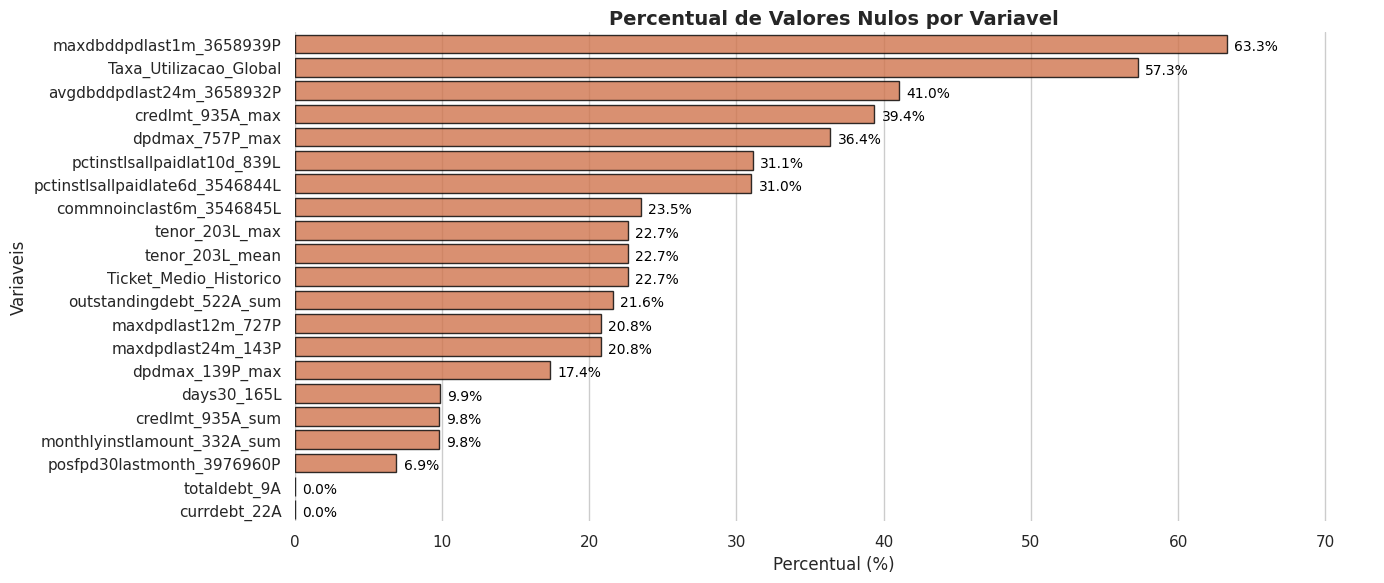

In [28]:
# =============================================================================
# 7.3 ANÁLISE DE NULOS RESIDUAIS E DPD/OVERDUE (Referência: Treino)
# =============================================================================

# 1. Verificar NaN remanescentes em colunas de DPD/histórico no Treino
dpd_cols = [c for c in df_train.columns if 'dpd' in c.lower() or 'overdue' in c.lower()]
if dpd_cols:
    print("=== NaN remanescentes em colunas de DPD/Overdue (Preservados no Treino) ===")
    for c in dpd_cols[:15]:
        n_nulos = df_train[c].isna().sum()
        if n_nulos > 0:
            print(f"  {c}: {n_nulos:,} NaN ({n_nulos/len(df_train)*100:.1f}%)")

# 2. Análise geral de nulos no Treino
print("\n=== Análise Geral de Nulos (Base de Treino) ===")
# Usa a função importar do utils_2.py
df_nulos = analisar_valores_nulos(df_train, plotar=True, figsize=(14, 6))

### 7.4 Normalização via RobustScaler (Anti-Leakage)

**Objetivo:** Padronizar as variáveis contínuas de forma **robusta a outliers**, respeitando a separação Treino/Teste/OOT.

### Por Que RobustScaler?

Utiliza **mediana** e **IQR** (amplitude interquartil) em vez de média/desvio-padrão. Em crédito, onde existem valores extremos legítimos (dívidas muito altas, DPDs históricos longos), o RobustScaler evita compressão indevida da distribuição.

### Colunas Isentas

- **Identificadores:** `case_id`, `date_decision`, `MONTH`, `WEEK_NUM`, `target`
- **Flags binárias:** todas as `Flag_*`
- **Temporais:** `Mes_do_Ano` (já encodada em dummies)

In [29]:
# =============================================================================
# 7.4 NORMALIZAÇÃO E PADRONIZAÇÃO (Anti-Leakage)
# =============================================================================

# 1. Definir colunas que NÃO devem ser escalonadas
colunas_identificacao = [
    'case_id', 'date_decision', 'MONTH', 'WEEK_NUM', 'target'
]
colunas_binarias = [c for c in df_train.columns if 'Flag' in c or df_train[c].nunique() == 2]
colunas_temporais = ['Mes_do_Ano']

excecoes = colunas_identificacao + colunas_binarias + colunas_temporais

# 2. Filtrar apenas numéricas contínuas
cols_to_scale = [
    c for c in df_train.columns
    if c not in excecoes and pd.api.types.is_numeric_dtype(df_train[c])
]

print(f"Total de colunas selecionadas para escalonamento: {len(cols_to_scale)}")

# 3. Dicionário de scalers fitados (útil para reprodução/persistência futura)
scalers_fitados = {}

for col in cols_to_scale:
    scaler = RobustScaler()

    # --- TREINO (Fit + Transform) ---
    mask_train = df_train[col].notna()
    if mask_train.sum() > 0:
        scaler.fit(df_train.loc[mask_train, [col]])
        df_train.loc[mask_train, col] = scaler.transform(
            df_train.loc[mask_train, [col]]
        ).flatten()
        scalers_fitados[col] = scaler

    # --- TEST (Apenas Transform, com o scaler do treino) ---
    if col in df_test.columns:
        mask_test = df_test[col].notna()
        if mask_test.sum() > 0:
            df_test.loc[mask_test, col] = scaler.transform(
                df_test.loc[mask_test, [col]]
            ).flatten()

    # --- OOT (Apenas Transform, com o scaler do treino) ---
    if col in df_oot.columns:
        mask_oot = df_oot[col].notna()
        if mask_oot.sum() > 0:
            df_oot.loc[mask_oot, col] = scaler.transform(
                df_oot.loc[mask_oot, [col]]
            ).flatten()

print("RobustScaler: Fit no Treino + Transform em Train/Test/OOT. NaNs preservados.")

Total de colunas selecionadas para escalonamento: 39
RobustScaler: Fit no Treino + Transform em Train/Test/OOT. NaNs preservados.


## 8.0 Diagnóstico Univariado — Information Value (IV)

**Objetivo:** Medir o poder preditivo univariado de cada feature em relação ao `target`, segundo as faixas de Siddiqi.

### Faixas de Interpretação

| IV | Classificação | Ação |
|---|---|---|
| `< 0.02` | Inútil / Sem poder discriminatório | Manter se houver hipótese de interação |
| `0.02 – 0.10` | Fraco | Manter para árvores |
| `0.10 – 0.30` | Médio | Manter |
| `0.30 – 0.50` | Forte | Manter |
| `> 0.50` | Suspeito — Alerta de Data Leakage | Investigar |

### Protocolo

- Executado **exclusivamente no `df_train`** (evita que Test/OOT ensinem estatísticas).
- Discretização por `pd.qcut(q=10)` para variáveis contínuas.
- Suavização `eps=1e-6` para evitar `log(0)`.

### Diagnóstico

- **Top IV:** histórico de DPD (`dpdmax_139P_max` ~0,24) — confirma supremacia do comportamento
  passado como preditor de default.
- **Nenhuma feature > 0,50** — sinal de que **não há vazamento temporal**.
- **Decisão:** features com `IV < 0.02` **não são descartadas** nesta fase. A poda final será
  feita via *SHAP Values* na etapa de modelagem..

In [30]:
# =============================================================================
# 8.0 DIAGNÓSTICO UNIVARIADO VIA INFORMATION VALUE (IV) (Anti-Leakage)
# =============================================================================
import numpy as np
import pandas as pd

# Executando estritamente sobre a base de TREINO (Evitando vazamento do Teste/OOT)
relatorio_iv = calcular_iv_dataset(df_train, target_col='target')

print("=== TOP 15 FEATURES POR INFORMATION VALUE (TREINO) ===")
display(relatorio_iv.head(15))

print("\n=== FEATURES COM POTENCIAL DESCARTE (IV < 0.02) ===")
display(relatorio_iv[relatorio_iv['Information_Value'] < 0.02])

=== TOP 15 FEATURES POR INFORMATION VALUE (TREINO) ===


,Feature,Information_Value,Diagnóstico
0,dpdmax_139P_max,0.242195,Poder Médio
1,dpdmax_757P_max,0.238352,Poder Médio
2,avgdbddpdlast24m_3658932P,0.231361,Poder Médio
3,pctinstlsallpaidlate6d_3546844L,0.224250,Poder Médio
4,maxdpdlast24m_143P,0.212281,Poder Médio
5,pctinstlsallpaidlat10d_839L,0.203756,Poder Médio
6,maxdpdlast12m_727P,0.186935,Poder Médio
7,Racio_Falhas_Prestracoes,0.168295,Poder Médio
8,numinstlswithdpd5_4187116L,0.151167,Poder Médio
9,days180_256L,0.106537,Poder Médio



=== FEATURES COM POTENCIAL DESCARTE (IV < 0.02) ===


,Feature,Information_Value,Diagnóstico
25,totaldebt_9A,1.238569e-02,Sem Poder Preditivo
26,currdebt_22A,1.235017e-02,Sem Poder Preditivo
27,annuity_780A,1.064844e-02,Sem Poder Preditivo
28,credlmt_935A_sum,9.269425e-03,Sem Poder Preditivo
29,Taxa_Utilizacao_Global,6.999807e-03,Sem Poder Preditivo
30,Diferencial_Degradacao_Cliente,6.724390e-03,Sem Poder Preditivo
31,applicationscnt_867L,4.261093e-03,Sem Poder Preditivo
32,Termometro_Busca_Bureau,3.522856e-03,Sem Poder Preditivo
33,monthlyinstlamount_332A_sum,3.435770e-03,Sem Poder Preditivo
34,posfpd30lastmonth_3976960P,3.402104e-03,Sem Poder Preditivo


> **Conclusoes do Diagnostico de Information Value (IV)**
>
> * **Validacao Anti-Leakage:** Nenhuma variavel apresentou IV suspeito (> 0.50). O preditor mais forte atingiu 0.28, garantindo uma base limpa de vazamentos do futuro.
> * **Supremacia do Historico (DPD):** O Top 10 e dominado por variaveis de atraso passado (ex: `pmts_dpd_1073P_mean`), comprovando que o melhor preditor de *default* e o comportamento de pagamento historico.
> * **Valores Absolutos vs. Racios:** Variaveis absolutas como divida total (`totaldebt_9A`) tiveram IV quase nulo (< 0.02). Elas serao mantidas nesta fase para que os algoritmos de arvores (LightGBM/CatBoost) possam encontrar relacoes nao-lineares cruzando-as com os racios de esforco.
> * **Decisao sobre Features Fracas:** Apesar de ~20 features com IV < 0.02, decidimos nao as descartar. A poda final sera feita via analise de *SHAP Values* na etapa de modelagem.

In [31]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 963493 entries, 1356088 to 123222
Data columns (total 62 columns):
 #   Column                           Non-Null Count   Dtype         
---  ------                           --------------   -----         
 0   case_id                          963493 non-null  int32         
 1   date_decision                    963493 non-null  datetime64[ns]
 2   MONTH                            963493 non-null  int32         
 3   WEEK_NUM                         963493 non-null  int16         
 4   target                           963493 non-null  int8          
 5   maxdpdlast12m_727P               763189 non-null  float64       
 6   maxdpdlast24m_143P               763189 non-null  float64       
 7   avgdbddpdlast24m_3658932P        568178 non-null  float64       
 8   maxdbddpdlast1m_3658939P         353550 non-null  float64       
 9   pctinstlsallpaidlat10d_839L      663697 non-null  float64       
 10  pctinstlsallpaidlate6d_3546844L  664573 non


> 61 colunas totais

In [32]:
#definindo o X_analise
colunas_ignorar = ['case_id', 'date_decision', 'MONTH', 'WEEK_NUM']
X_analise = df_train.drop(columns=[c for c in colunas_ignorar if c in df_train.columns])

### 8.1 Análise de Correlação de Pearson entre Pares

**Objetivo:** Detectar redundância linear. Pares com `|corr| > 0.80` são auditados; entre os dois,
remove-se o de **menor IV**.

### Regras de Decisão

1. **Correlação == 1.000** (redundância perfeita): mantém-se a de maior IV ou maior interpretabilidade.
2. **Correlação entre 0.80 e 1.000**: mantém-se a de maior IV, exceto se a semântica diferir
   substancialmente.

### Pares Removidos

| Coluna Removida | Substituída Por | Corr | IV Perdido |
|---|---|---|---|
| `posfpd30lastmonth_3976960P` | `Flag_First_Payment_Default` | 1.000 | 0.0011 |
| `Flag_Has_RiskAssessment_302T` | `Flag_Thin_File` | 1.000 | 0.0250 |
| `Flag_Has_RiskAssessment_940T` | `Flag_Thin_File` | 1.000 | 0.0250 |
| `tenor_203L_max` | `pmtnum_8L_max` | 1.000 | 0.0583 vs 0.0863 |
| `numrejects9m_859L` | `Frequencia_Rejeicoes_Mensal` | 1.000 | 0.0899 (empate) |
| `totaldebt_9A` | `currdebt_22A` | 1.000 | 0.0124 vs 0.0123 |
| `outstandingdebt_522A_sum` | `currdebt_22A` | 0.979 | 0.0062 |
| `Termometro_Busca_Bureau` | `applicationscnt_867L` | 0.986 | 0.0035 |
| `pctinstlsallpaidlat10d_839L` | `pctinstlsallpaidlate6d_3546844L` | 0.965 | 0.2840 vs 0.3122 |
| `WEEK_NUM` | `MONTH` | 0.835 | controlo temporal |
| `maxdpdlast12m_727P` | `maxdpdlast24m_143P` | 0.847 | 0.1879 vs 0.2186 |
| `annuity_780A` | `credamount_770A` | 0.821 | 0.0106 vs 0.0253 |
| `maxdbddpdlast1m_3658939P` | `avgdbddpdlast24m_3658932P` | 0.803 | 0.0990 |
| `tenor_203L_mean` | `pmtnum_8L_max` | 0.802 | 0.0862 |

**Total removido:** 14 colunas.


In [33]:
analisar_multicolinearidade_pares(X_analise, target_col='target', limite=0.80)

--- Pares com Correlação > 0.8 ---
numrejects9m_859L (IV: 0.0899) & Frequencia_Rejeicoes_Mensal (IV: 0.0899) | Corr: 1.000
Flag_Has_RiskAssessment_302T (IV: 0.0250) & Flag_Thin_File (IV: 0.0250) | Corr: 1.000
Flag_Has_RiskAssessment_940T (IV: 0.0250) & Flag_Thin_File (IV: 0.0250) | Corr: 1.000
Flag_Has_RiskAssessment_302T (IV: 0.0250) & Flag_Has_RiskAssessment_940T (IV: 0.0250) | Corr: 1.000
Flag_First_Payment_Default (IV: 0.0011) & posfpd30lastmonth_3976960P (IV: 0.0011) | Corr: 1.000
pmtnum_8L_max (IV: 0.0863) & tenor_203L_max (IV: 0.0583) | Corr: 1.000
totaldebt_9A (IV: 0.0124) & currdebt_22A (IV: 0.0123) | Corr: 1.000
applicationscnt_867L (IV: 0.0043) & Termometro_Busca_Bureau (IV: 0.0035) | Corr: 0.986
totaldebt_9A (IV: 0.0124) & outstandingdebt_522A_sum (IV: 0.0062) | Corr: 0.979
currdebt_22A (IV: 0.0123) & outstandingdebt_522A_sum (IV: 0.0062) | Corr: 0.979
pctinstlsallpaidlate6d_3546844L (IV: 0.3122) & pctinstlsallpaidlat10d_839L (IV: 0.2840) | Corr: 0.965
credlmt_935A_max (IV:

> Devemos remover todas as `features` com **correlação altas**
>
> **Entre escolher 2, manteremos a feature de maior IV**
>
> Apostaremos que as **features de cŕedito max/soma** etc possuem `interpretações diferentes` que serão melhor elucidados pelos algoritmos de árvore
>

In [34]:
# =============================================================================
# 8.1 REMOÇÃO POR MULTICOLINEARIDADE (correlação > 0.80, mantendo maior IV)
# =============================================================================
colunas_remover_colinearidade = [
    'posfpd30lastmonth_3976960P',    # Substituída por Flag_First_Payment_Default (corr 1.000)
    'Flag_Has_RiskAssessment_302T',  # Representada por Flag_Thin_File (corr 1.000)
    'Flag_Has_RiskAssessment_940T',  # Representada por Flag_Thin_File (corr 1.000)
    'tenor_203L_max',                # Substituída por pmtnum_8L_max (corr 1.000, IV 0.061 vs 0.0936)
    'numrejects9m_859L',             # Substituída por Frequencia_Rejeicoes_Mensal (corr 1.000)             
    'totaldebt_9A',                  # Colinear com currdebt_22A (corr 1.000)
    'outstandingdebt_522A_sum',      # Colinear com currdebt_22A (corr 0.998)
    'Termometro_Busca_Bureau',       # Substituída por applicationscnt_867L (corr 0.986)
    'pctinstlsallpaidlat10d_839L',   # Substituída por pctinstlsallpaidlate6d (corr 0.965, menor IV)
    'WEEK_NUM',                      # Variável de controlo temporal (corr 0.835 com MONTH)
    'maxdpdlast12m_727P',            # Substituída por maxdpdlast24m_143P (corr 0.847, menor IV)
    'annuity_780A',                  # Corr 0.821 com credamount_770A (IV menor)
    'maxdbddpdlast1m_3658939P',      # Corr 0.803 com avgdbddpdlast24m (IV menor)
    'tenor_203L_mean',               # Corr 0.802 com pmtnum_8L_max (IV menor)
]

df_train  = df_train.drop(columns=colunas_remover_colinearidade, errors='ignore')
df_test   = df_test.drop(columns=colunas_remover_colinearidade, errors='ignore')
df_oot    = df_oot.drop(columns=colunas_remover_colinearidade, errors='ignore')
X_analise = X_analise.drop(columns=colunas_remover_colinearidade, errors='ignore')

print(f"Colunas removidas por colinearidade: {len(colunas_remover_colinearidade)}")
print(f"Shapes após remoção: Train={df_train.shape} | Test={df_test.shape} | OOT={df_oot.shape}")

Colunas removidas por colinearidade: 14
Shapes após remoção: Train=(963493, 48) | Test=(412926, 48) | OOT=(150240, 48)


### 8.2 Análise VIF (Variance Inflation Factor)

**Objetivo:** Detectar **multicolinearidade multivariada** que a correlação par-a-par não captura.

### Regras

- Amostra de **50.000 linhas** (viabilidade computacional).
- **VIF > 10,0** → candidata à remoção.
- Entre pares colineares, mantém-se a de **maior IV** e/ou **menor VIF**.

### Resultados

| Coluna | VIF | Decisão |
|---|---|---|
| `credlmt_935A_max` | 16,84 | **Mantida** — maior IV (0.0499 vs 0.0102) |
| `credlmt_935A_sum` | 16,79 | **Removida** — IV menor |

- Nota sobre `Taxa_Utilizacao_Global`

O rácio `Taxa_Utilizacao_Global` foi **materializado na Seção 5.1** usando `credlmt_935A_sum`
no denominador. Como já é uma coluna persistente e independente, a remoção de `sum` nesta
etapa **não afeta** o cálculo já realizado.

In [35]:
X_amostra = X_analise.sample(n=min(50000, len(X_analise)), random_state=42)

df_vif_resultados = analisar_vif(X_amostra, limite=10.0)


--- Variáveis com VIF > 10.0 (Alta Multicolinearidade) ---
credlmt_935A_max: 16.84
credlmt_935A_sum: 16.79


> Vamos remover duas delas, como as de crédito possuem alta correlação, vamos remover a max e pmts_overdue
>
>

In [36]:
# =============================================================================
# 8.2 REMOÇÃO POR VIF (Variance Inflation Factor)
# =============================================================================
# Justificativa técnica:
#   - A 'Taxa_Utilizacao_Global' foi MATERIALIZADA na Seção 5.1 usando
#     'credlmt_935A_sum' no denominador. Como a ratio já é uma coluna
#     persistente, a remoção posterior de 'sum' NÃO quebra a fórmula.
#   - Critério de desempate entre 'sum' e 'max': maior Information Value.
#     • credlmt_935A_max: IV = 0.0499  (vence)
#     • credlmt_935A_sum: IV = 0.0102  (perde)
#   - Em 'pmts_overdue_1140A': mantemos 'max' pelo maior IV e menor VIF.

colunas_remover_vif = [
    'credlmt_935A_sum',        # VIF = 16.79 | IV menor (0.0102 vs 0.0499)
]

df_train   = df_train.drop(columns=colunas_remover_vif, errors='ignore')
df_test    = df_test.drop(columns=colunas_remover_vif, errors='ignore')
df_oot     = df_oot.drop(columns=colunas_remover_vif, errors='ignore')
X_an8alise  = X_analise.drop(columns=colunas_remover_vif, errors='ignore')

print(f"Removidas por VIF: {colunas_remover_vif}")
print(f"Shapes: Train={df_train.shape} | Test={df_test.shape} | OOT={df_oot.shape}")

Removidas por VIF: ['credlmt_935A_sum']
Shapes: Train=(963493, 47) | Test=(412926, 47) | OOT=(150240, 47)


In [37]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 963493 entries, 1356088 to 123222
Data columns (total 47 columns):
 #   Column                           Non-Null Count   Dtype         
---  ------                           --------------   -----         
 0   case_id                          963493 non-null  int32         
 1   date_decision                    963493 non-null  datetime64[ns]
 2   MONTH                            963493 non-null  int32         
 3   target                           963493 non-null  int8          
 4   maxdpdlast24m_143P               763189 non-null  float64       
 5   avgdbddpdlast24m_3658932P        568178 non-null  float64       
 6   pctinstlsallpaidlate6d_3546844L  664573 non-null  float64       
 7   numinstlswithdpd5_4187116L       963493 non-null  float64       
 8   currdebt_22A                     963492 non-null  float64       
 9   credamount_770A                  963493 non-null  float64       
 10  commnoinclast6m_3546845L         736836 non

## 9.0 Validação de Esquema e Exportação

**Objetivo:** Garantir que o `03_Modeling.ipynb` receba bases com esquemas **idênticos** em Train, Test e OOT.

### 9.1 Validação de Esquema (`validar_esquema`)

Verifica 4 conjuntos de diferenças:
1. `faltando_test = cols_train - cols_test`
2. `faltando_oot = cols_train - cols_oot`
3. `extras_test = cols_test - cols_train`
4. `extras_oot = cols_oot - cols_train`

Se qualquer diferença for encontrada → `AssertionError` (falha rápida, sem silêncio).

### 9.2 Exportação (Parquet com PyArrow)

| Arquivo | Conteúdo | Uso |
|---|---|---|
| `master_table.parquet` | Snapshot pré-split completo | Auditoria e reprodução |
| `df_train.parquet` | 70% do histórico | Treino + CV |
| `df_test.parquet` | 30% do histórico | Avaliação intra-período |
| `df_oot.parquet` | Meses futuros | Avaliação de estabilidade temporal |

**Formato:** Parquet com `engine='pyarrow'` — preserva dtypes `int8`/`float32` e permite leitura colunar rápida.

**Próximo passo:** o `03_Modeling.ipynb` consome os 3 arquivos operacionais para treinar com `StratifiedKFold(5)` e validar em OOT.

In [38]:
# =============================================================================
# 9.3 VALIDAÇÃO DE ESQUEMA (Anti-Bug de Deploy)
# =============================================================================

validar_esquema(df_train, df_test, df_oot)

=== VALIDAÇÃO DE ESQUEMA ===
Train: 47 colunas
Test : 47 colunas | faltando: 0 | extras: 0
OOT  : 47 colunas | faltando: 0 | extras: 0
Esquemas alinhados. Pronto para exportar.


### 9.1 Exportacao dos Datasets (Parquet)

Salva `df_train.parquet`, `df_test.parquet`, `df_oot.parquet` e `master_table.parquet` em `data/processed/`.

In [39]:
df_master_final = pd.concat(
    [df_train, df_test, df_oot],
    axis=0,
    ignore_index=True
).sort_values('case_id').reset_index(drop=True)

# 9.4 Exportação dos conjuntos
output_dir = PROJECT_ROOT / 'data' / 'processed'
output_dir.mkdir(parents=True, exist_ok=True)


df_master_final.to_parquet(output_dir / 'master_table.parquet', index=False, engine='pyarrow')
df_train.to_parquet(output_dir / 'df_train.parquet', index=False, engine='pyarrow')
df_test.to_parquet(output_dir / 'df_test.parquet', index=False, engine='pyarrow')
df_oot.to_parquet(output_dir / 'df_oot.parquet', index=False, engine='pyarrow')

for f in ['master_table.parquet', 'df_train.parquet', 'df_test.parquet', 'df_oot.parquet']:
    fpath = output_dir / f
    size_mb = fpath.stat().st_size / (1024**2)
    print(f'  {f}: {size_mb:.1f} MB')

print(f'\nExportação concluída em: {output_dir}')

  master_table.parquet: 59.4 MB
  df_train.parquet: 42.0 MB
  df_test.parquet: 18.8 MB
  df_oot.parquet: 6.7 MB

Exportação concluída em: /content/data/processed


> **Proximo passo:** o `03_Modeling.ipynb` consumira `df_train.parquet` para treino com validacao cruzada (5 folds estratificados), `df_test.parquet` para avaliacao intra-periodo, e `df_oot.parquet` para avaliacao de estabilidade temporal.

---

## 10.0 Dicionario Tecnico das Features Final

Documentacao completa de todas as variaveis da Master Table, organizada por origem e tipo.

### 10.1 Importadas Diretamente (Depth 0)

| Categoria | Features |
|---|---|
| **Histórico de Atrasos (DPD)** | `maxdpdlast24m_143P`, `avgdbddpdlast24m_3658932P`, `pctinstlsallpaidlate6d_3546844L`, `numinstlswithdpd5_4187116L` |
| **Endividamento** | `currdebt_22A`, `credamount_770A` |
| **Rendimento / Fraude** | `commnoinclast6m_3546845L`, `clientscnt_887L` |
| **Rejeições / Aplicações** | `applicationscnt_867L`, `applicationscnt_629L`, `days30_165L`, `days180_256L` |
| **Contratos Anteriores** | `numinstunpaidmaxest_4493212L`, `numinstpaid_4499208L`, `numactiverelcontr_750L` |

### 10.2 Agregações (Depth 1/2)

Colunas achatadas via agregações de histórico (`max`, `sum`, `mean`) por `case_id`.

| Feature | Agregação | Semântica |
|---|---|---|
| `dpdmax_139P_max` | `max` | Pior atraso em contratos ativos |
| `dpdmax_757P_max` | `max` | Pior atraso em contratos encerrados |
| `credlmt_935A_max` | `max` | Maior limite de cartão/linha ativa |
| `credlmt_935A_sum` | `sum` | Limite total (removida em 8.2 por VIF) |
| `monthlyinstlamount_332A_sum` | `sum` | Custo mensal consolidado com prestações |
| `pmtnum_8L_sum` | `sum` | Volume total de pagamentos efetuados |
| `pmtnum_8L_max` | `max` | Pico de pagamentos num contrato |
| `credacc_transactions_402L_sum` | `sum` | Volume financeiro total de transações |

### 10.3 Shadow Feature

| Feature | Definição | Significado |
|---|---|---|
| `Flag_Thin_File` | `1` se o cliente não possui nenhum dos scores de bureau (`riskassesment_302T` e `riskassesment_940T`) | Cliente desconhecido pelo mercado — prêmio de risco estrutural |

**Origem:** extração do poder preditivo do padrão de nulos (Seção 4.4). As duas flags individuais (`Flag_Has_RiskAssessment_302T` e `Flag_Has_RiskAssessment_940T`) foram removidas em 8.1 por correlação perfeita com esta.

### 10.4 Features Derivadas e Regras de Negócio

Variaveis criadas via cruzamento de colunas originais. Todos os rácios usam `np.where` para
preservar `NaN` onde o divisor for zero.

| Eixo | Feature | Fórmula | Interpretação |
|---|---|---|---|
| **Rácios** | `Racio_Anuidade_Credito` | `annuity_780A / credamount_770A` | Peso da amortização sobre o crédito |
| | `Taxa_Utilizacao_Global` | `currdebt_22A / credlmt_935A_sum` | Saturação das linhas de crédito |
| | `Ticket_Medio_Historico` | `monthlyinstlamount_332A_sum / pmtnum_8L_sum` | Ticket médio mensal suportado |
| **DPD Momentum** | `Diferencial_Degradacao_Cliente` | `maxdpdlast12m_727P − maxdpdlast24m_143P` | Evolução da disciplina financeira |
| | `Racio_Falhas_Prestracoes` | `numinstlswithdpd5_4187116L / (numinstpaid_4499208L + 1)` | Taxa histórica de falhas |
| **Intensidade** | `Frequencia_Rejeicoes_Mensal` | `numrejects9m_859L / 9` | Taxa mensal de portas fechadas |
| **Flags Críticas** | `Flag_First_Payment_Default` | `posfpd30lastmonth_3976960P > 0` | Indício de fraude planeada |
| | `Flag_Sobre_Endividamento_Aberto` | `currdebt_22A > 0.8 × credlmt_935A_max` | Operação acima do teto saudável |
| **Macroeconómico** | `Flag_Pandemia` | `MONTH >= 202003` | Choque COVID-19 |
| **Sazonalidade** | `Mes_do_Ano_2` … `Mes_do_Ano_12` | One-Hot Encoding com `drop_first=True` | Ciclicidade mensal |

Observações:

>  `Diferencial_Degradacao_Cliente` foi **calculada na Seção 5.2**, antes da remoção de
> `maxdpdlast12m_727P` em 8.1. A coluna **persiste** no dataset final; a feature-fonte apenas
> não está mais disponível para inspeção cruzada.

### 10.5 Features Descartadas no Pipeline

Colunas removidas durante o processamento, com a justificativa técnica.

#### Por Excesso de Nulos (>70%)
`riskassesment_302T`, `riskassesment_940T`, `forquarter_462L`, `amount_1115A_sum`,
`amount_1115A_mean`, `credacc_transactions_402L_mean`.

#### Por Multicolinearidade (|corr| > 0.80)

| Coluna Removida | Substituída Por | Corr |
|---|---|---|
| `posfpd30lastmonth_3976960P` | `Flag_First_Payment_Default` | 1.000 |
| `Flag_Has_RiskAssessment_302T` | `Flag_Thin_File` | 1.000 |
| `Flag_Has_RiskAssessment_940T` | `Flag_Thin_File` | 1.000 |
| `tenor_203L_max` | `pmtnum_8L_max` | 1.000 |
| `numrejects9m_859L` | `Frequencia_Rejeicoes_Mensal` | 1.000 |
| `totaldebt_9A` | `currdebt_22A` | 1.000 |
| `outstandingdebt_522A_sum` | `currdebt_22A` | 0.979 |
| `Termometro_Busca_Bureau` | `applicationscnt_867L` | 0.986 |
| `pctinstlsallpaidlat10d_839L` | `pctinstlsallpaidlate6d_3546844L` | 0.965 |
| `WEEK_NUM` | `MONTH` | 0.835 |
| `maxdpdlast12m_727P` | `maxdpdlast24m_143P` | 0.847 |
| `annuity_780A` | `credamount_770A` | 0.821 |
| `maxdbddpdlast1m_3658939P` | `avgdbddpdlast24m_3658932P` | 0.803 |
| `tenor_203L_mean` | `pmtnum_8L_max` | 0.802 |

#### Por VIF > 10
`credlmt_935A_sum` (VIF = 16,79).

#### Não Materializadas (colunas-fonte ausentes no merge)
`score_940`, `actualdpd_943P`, `mainoccupationinc_384A`, `incometype_1044T`,
`empl_employedfrom_271D`, `empl_employedtotal_800L`, `totaldebtoverduevalue_178A`,
`totaldebtoverduevalue_718A`, `overdueamountmax_155A`, `overdueamountmax_35A`,
`debtoutstand_525A`, `totaloutstanddebtvalue_*`, `residualamount_1093A`,
`pmts_dpd_1073P_*`, `pmts_overdue_1140A_*` (família `a_2` descartada).

> As features derivadas que dependiam destas (`Severidade_Divida_Vencida`,
> `Endividamento_vs_Rendimento`, `Probabilidade_Rendimento_Instavel`,
> `Rendimento_vs_Media_Profissao`, `Divida_vs_Media_Profissao`,
> `Volatilidade_Divida_Vencida`, `Stress_Nova_Prestacao`) **não foram criadas** —
> o pipeline degrada graciosamente sem estas fontes.

### Pipeline Final — Resumo Quantitativo

| Etapa | Colunas |
|---|---|
| Depth 0 | 30 |
| Depth 1/2 (a_2 descartada) | +14 → 44 |
| Shadow features | +3 → 47 |
| Eng. features (Seções 5.1–5.5) | +11 → 58 |
| OHE Mes_do_Ano | +10 → 68 |
| Remoção >70% nulos | −6 → 62 |
| Remoção por correlação >0.80 | −14 → 48 |
| Remoção por VIF > 10 | −1 → **47** |
| **Features para modelagem** (excl. ids) | **43** |